# ML8. Neural Networks


In [3]:
import numpy as np
import pandas as pd
import os
import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 21
rng = np.random.default_rng(RANDOM_STATE)

DATA_PATH = "data/training.csv"
TARGET_COL = "IsBadBuy"
DATE_COL = "PurchDate"


## Предобработка данных

train/valid/test split

Требования:
- Использовать поле `PurchDate` для сплита: `train.PurchDate < valid.PurchDate < test.PurchDate`.
- Первые 33% дат — train, последние 33% — test, средние 33% — valid.
- Категориальные переменные кодируем `LabelEncoder`/`OneHotEncoder`, обучая энкодер **только на train**, чтобы не допустить утечки данных.
- Отдельно обрабатываем случай, когда в valid/test встречается категория, которой не было в train.


In [4]:
df = pd.read_csv('training.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68669 entries, 0 to 68668
Data columns (total 34 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   RefId                              68669 non-null  int64  
 1   IsBadBuy                           68669 non-null  int64  
 2   PurchDate                          68669 non-null  object 
 3   Auction                            68669 non-null  object 
 4   VehYear                            68669 non-null  int64  
 5   VehicleAge                         68669 non-null  int64  
 6   Make                               68669 non-null  object 
 7   Model                              68669 non-null  object 
 8   Trim                               66524 non-null  object 
 9   SubModel                           68667 non-null  object 
 10  Color                              68667 non-null  object 
 11  Transmission                       68666 non-null  obj

In [5]:
def time_based_split(df, date_col=DATE_COL, fracs=(1/3, 1/3, 1/3)):
    df = df.copy()
    df[date_col] = pd.to_datetime(df[date_col])
    df = df.sort_values(by=date_col).reset_index(drop=True)

    n = len(df)
    n_train = int(n * fracs[0])
    n_valid = int(n * (fracs[0] + fracs[1]))

    train = df.iloc[:n_train].copy()
    valid = df.iloc[n_train:n_valid].copy()
    test = df.iloc[n_valid:].copy()

    assert train[date_col].max() <= valid[date_col].min()
    assert valid[date_col].max() <= test[date_col].min()

    return train, valid, test


train_df, valid_df, test_df = time_based_split(df)
print("train:", train_df.shape, train_df[DATE_COL].min(), "->", train_df[DATE_COL].max())
print("valid:", valid_df.shape, valid_df[DATE_COL].min(), "->", valid_df[DATE_COL].max())
print("test :", test_df.shape, test_df[DATE_COL].min(), "->", test_df[DATE_COL].max())
print("train target rate:", train_df[TARGET_COL].mean().round(3))
print("valid target rate:", valid_df[TARGET_COL].mean().round(3))
print("test  target rate:", test_df[TARGET_COL].mean().round(3))

train: (22889, 34) 2009-01-05 00:00:00 -> 2009-09-18 00:00:00
valid: (22890, 34) 2009-09-18 00:00:00 -> 2010-05-20 00:00:00
test : (22890, 34) 2010-05-20 00:00:00 -> 2010-12-30 00:00:00
train target rate: 0.113
valid target rate: 0.128
test  target rate: 0.123


In [6]:
drop_cols = [c for c in ["RefId", DATE_COL, TARGET_COL] if c in df.columns]
feature_cols = [c for c in df.columns if c not in drop_cols]

cat_cols = [c for c in feature_cols if pd.api.types.is_string_dtype(df[c]) or df[c].dtype == object]
num_cols = [c for c in feature_cols if c not in cat_cols]

print("Категориальные признаки:", cat_cols)
print("Числовые признаки:", num_cols)


Категориальные признаки: ['Auction', 'Make', 'Model', 'Trim', 'SubModel', 'Color', 'Transmission', 'WheelType', 'Nationality', 'Size', 'TopThreeAmericanName', 'PRIMEUNIT', 'AUCGUART', 'VNST']
Числовые признаки: ['VehYear', 'VehicleAge', 'WheelTypeID', 'VehOdo', 'MMRAcquisitionAuctionAveragePrice', 'MMRAcquisitionAuctionCleanPrice', 'MMRAcquisitionRetailAveragePrice', 'MMRAcquisitonRetailCleanPrice', 'MMRCurrentAuctionAveragePrice', 'MMRCurrentAuctionCleanPrice', 'MMRCurrentRetailAveragePrice', 'MMRCurrentRetailCleanPrice', 'BYRNO', 'VNZIP1', 'VehBCost', 'IsOnlineSale', 'WarrantyCost']


Кодируем категориальные признаки:

In [7]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder

cat_cols = train_df.select_dtypes(include=["object"]).columns.tolist()

print("Категориальные признаки:")
print(cat_cols)

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

ohe.fit(train_df[cat_cols])
X_train_cat = ohe.transform(train_df[cat_cols])
X_valid_cat = ohe.transform(valid_df[cat_cols])
X_test_cat = ohe.transform(test_df[cat_cols])

print("Train:", X_train_cat.shape)
print("Validation:", X_valid_cat.shape)
print("Test:", X_test_cat.shape)

Категориальные признаки:
['Auction', 'Make', 'Model', 'Trim', 'SubModel', 'Color', 'Transmission', 'WheelType', 'Nationality', 'Size', 'TopThreeAmericanName', 'PRIMEUNIT', 'AUCGUART', 'VNST']
Train: (22889, 1680)
Validation: (22890, 1680)
Test: (22890, 1680)


Стандартизируем численные признаки:

In [8]:
from sklearn.preprocessing import StandardScaler

X_train_num_raw = train_df[num_cols].fillna(train_df[num_cols].median()).to_numpy(dtype=np.float32)
train_num_median = train_df[num_cols].median()
X_valid_num_raw = valid_df[num_cols].fillna(train_num_median).to_numpy(dtype=np.float32)
X_test_num_raw = test_df[num_cols].fillna(train_num_median).to_numpy(dtype=np.float32)

scaler = StandardScaler().fit(X_train_num_raw)
X_train_num = scaler.transform(X_train_num_raw)
X_valid_num = scaler.transform(X_valid_num_raw)
X_test_num = scaler.transform(X_test_num_raw)

X_train = np.hstack([X_train_num, X_train_cat]).astype(np.float32)
X_valid = np.hstack([X_valid_num, X_valid_cat]).astype(np.float32)
X_test = np.hstack([X_test_num, X_test_cat]).astype(np.float32)

y_train = train_df[TARGET_COL].to_numpy(dtype=np.float32)
y_valid = valid_df[TARGET_COL].to_numpy(dtype=np.float32)
y_test = test_df[TARGET_COL].to_numpy(dtype=np.float32)

print("Финальные размерности:")
print("X_train:", X_train.shape, "X_valid:", X_valid.shape, "X_test:", X_test.shape)


Финальные размерности:
X_train: (22889, 1697) X_valid: (22890, 1697) X_test: (22890, 1697)


## Реализация класса MLP


## Функции активации

ReLU (Rectified Linear Unit)

    f(z) = max(0, z)
    f′(z) = 1 при z > 0;  f′(z) = 0 при z ≤ 0

Плюсы: мгновенное вычисление, градиент не затухает при положительных входах, стандартный выбор для скрытых слоёв.
Минусы: «проблема умирающих ReLU» — если вход нейрона всегда отрицателен, его градиент всегда равен нулю и нейрон перестаёт обучаться.

Leaky ReLU и PReLU

    f(z) = z            при z > 0
    f(z) = α·z          при z ≤ 0,  α ≈ 0,01

Небольшой ненулевой градиент при отрицательных входах устраняет «умирание». В PReLU коэффициент α является обучаемым параметром.

Sigmoid (логистическая функция)

    σ(z) = 1 / (1 + e^(−z))
    σ′(z) = σ(z)·(1 − σ(z))

Сжимает значения в диапазон (0; 1) — удобно, когда выход трактуется как вероятность. Минус: при больших |z| производная почти нулевая, максимальное значение производной всего 0,25 — в глубоких сетях возникает затухающий градиент. В скрытых слоях сейчас почти не используется; применяется на выходе для бинарной классификации.

Tanh (гиперболический тангенс)

    tanh(z) = (e^z − e^(−z)) / (e^z + e^(−z))

Диапазон (−1; 1), нулевой центр выходов — среднее активаций около нуля упрощает обучение следующего слоя. Затухание градиента сохраняется, но выражено слабее, чем у сигмоиды.

Softmax

Применяется на выходе многоклассовой классификации; превращает вектор в распределение вероятностей с суммой, равной 1:

    softmax(z)ᵢ = e^(zᵢ) / ∑ⱼ e^(zⱼ)

GELU и SiLU (Swish)

Гладкие варианты ReLU без резкого «обрыва» на нуле:

    SiLU(z) = z · σ(z)

Стандарт в современных архитектурах (в том числе трансформерах); обычно чуть лучше ReLU по качеству, но дороже по вычислениям.

Практические правила выбора

- Скрытые слои: ReLU, Leaky ReLU или GELU.
- Выход для регрессии: линейная функция (без активации).
- Бинарная классификация: sigmoid.
- Многоклассовая классификация: softmax.

In [9]:
def sigmoid(z):
    z = np.clip(z, -30, 30)
    return 1.0 / (1.0 + np.exp(-z))

def sigmoid_grad(z):
    s = sigmoid(z)
    return s * (1 - s)

def relu(z):
    return np.maximum(0, z)

def relu_grad(z):
    return (z > 0).astype(z.dtype)

def cosine(z):
    return np.cos(z)

def cosine_grad(z):
    return -np.sin(z)

def tanh_act(z):
    return np.tanh(z)

def tanh_grad(z):
    return 1 - np.tanh(z) ** 2

ACTIVATIONS = {
    "sigmoid": (sigmoid, sigmoid_grad),
    "relu": (relu, relu_grad),
    "cosine": (cosine, cosine_grad),
    "tanh": (tanh_act, tanh_grad),
}


def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


## Методы инициализация весов

Цель — сохранить масштаб сигналов и градиентов при проходе через слои.

- **Xavier/Glorot** — для sigmoid и tanh. Дисперсия подобрана так, чтобы дисперсия сигнала сохранялась в обоих направлениях:

      w ~ U(−c; c),  где c = √(6 / (n_in + n_out))

- **He (Kaiming)** — для ReLU-семейства; компенсирует «обнуление» половины сигналов:

      w ~ N(0; 2/n_in)

- Смещения инициализируются нулями. Инициализация нулями или одинаковыми числами не работает: нейроны слоя будут симметричны и выучат одно и то же.
- **Ортогональная инициализация** — сохраняет длины векторов; применяется в рекуррентных сетях.

Согласование активации и инициализации: sigmoid/tanh — Xavier; ReLU/Leaky ReLU — He; GELU/SiLU — обычно He.

## Методы оптимизации весов:

## Базовые варианты градиентного спуска

**Пакетный градиентный спуск (Batch Gradient Descent, BGD)** — обновление весов происходит после вычисления градиента по всему обучающему набору данных.  

**Преимущества:** стабильное направление шага, точная оценка градиента.  
**Недостатки:** высокая вычислительная стоимость и необходимость обрабатывать весь датасет на каждой итерации.

---

**Стохастический градиентный спуск (Stochastic Gradient Descent, SGD)** — обновление выполняется после каждого отдельного примера.  

**Преимущества:** быстрая сходимость на ранних этапах, способность «выпрыгивать» из локальных минимумов за счёт шума.  
**Недостатки:** сильная нестабильность траектории и риск колебаний вокруг оптимума.

---

**Мини-пакетный градиентный спуск (Mini-batch GD)** — компромиссный вариант: градиент усредняется по небольшому подмножеству данных (например, 32–256 примеров).  

Это наиболее распространённый режим в современных фреймворках благодаря балансу между стабильностью и скоростью.

---

## Методы с накоплением инерции (Momentum)

**SGD с моментом (Momentum)** — добавляет «инерцию», учитывая предыдущие направления обновления. Это помогает ускоряться в плоских областях и сглаживать колебания.

---

**Ускоренный градиент Нестерова (Nesterov Accelerated Gradient, NAG)** — предсказывает будущее положение параметров и вычисляет градиент в этой точке, а не в текущей.  

Это даёт более точную корректировку и ускоряет сходимость в овражистых областях.

---

## Адаптивные методы (автоматическая настройка шага для каждого веса)

**AdaGrad** — адаптирует скорость обучения для каждого параметра пропорционально сумме квадратов прошлых градиентов.  

Хорошо работает на разреженных данных, но шаг может слишком быстро затухать.

---

**RMSProp** — решает проблему затухания шага в AdaGrad, используя экспоненциальное скользящее среднее квадратов градиентов.  

Это позволяет поддерживать стабильный шаг даже после многих итераций.

---

**Adam (Adaptive Moment Estimation)** — комбинирует идеи Momentum и RMSProp: использует скользящие средние градиентов и квадратов градиентов.  

Adam — один из самых популярных оптимизаторов благодаря быстрой сходимости и устойчивости.

---

**AdamW** — модификация Adam с правильной L2‑регуляризацией (весовым затуханием), которая не смешивается с адаптацией шага. Это улучшает обобщающую способность модели.

In [14]:
class MLP:
    def __init__(self, n_hidden=100, activation="sigmoid", optimizer="adam",
                 lr=0.01, batch_size=32, n_epochs=20, l2=1e-4,
                 random_state=21, verbose=False,
                 beta1=0.9, beta2=0.999, eps=1e-8, momentum=0.9):
        self.n_hidden = n_hidden
        self.activation = activation
        self.optimizer = optimizer
        self.lr = lr
        self.batch_size = batch_size
        self.n_epochs = n_epochs
        self.l2 = l2
        self.random_state = random_state
        self.verbose = verbose
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.momentum = momentum

    def _resolve_activation(self):
        if isinstance(self.activation, str):
            return ACTIVATIONS[self.activation]
        else:
            act_fn = self.activation

            def numeric_grad(z, h=1e-5):
                return (act_fn(z + h) - act_fn(z - h)) / (2 * h)

            return act_fn, numeric_grad

    def _init_params(self, n_features):
        rng = np.random.default_rng(self.random_state)
        limit1 = np.sqrt(2.0 / (n_features + self.n_hidden))
        limit2 = np.sqrt(2.0 / (self.n_hidden + 2))
        self.W1 = rng.normal(0, limit1, size=(n_features, self.n_hidden)).astype(np.float64)
        self.b1 = np.zeros((1, self.n_hidden))
        self.W2 = rng.normal(0, limit2, size=(self.n_hidden, 2)).astype(np.float64)
        self.b2 = np.zeros((1, 2))

    def _init_optimizer_state(self):
        self._m = {k: np.zeros_like(v) for k, v in self._params().items()}
        self._v = {k: np.zeros_like(v) for k, v in self._params().items()}
        self._t = 0

    def _params(self):
        return {"W1": self.W1, "b1": self.b1, "W2": self.W2, "b2": self.b2}

    def _forward(self, X):
        z1 = X @ self.W1 + self.b1
        a1 = self.act_fn(z1)
        z2 = a1 @ self.W2 + self.b2
        y_hat = softmax(z2)
        cache = (X, z1, a1, z2, y_hat)
        return y_hat, cache

    def _backward(self, cache, y_batch):
        X, z1, a1, z2, y_hat = cache
        n = X.shape[0]
        y_onehot = np.zeros_like(y_hat)
        y_onehot[np.arange(n), y_batch.astype(int)] = 1.0

        dz2 = (y_hat - y_onehot) / n
        dW2 = a1.T @ dz2 + self.l2 * self.W2
        db2 = dz2.sum(axis=0, keepdims=True)

        da1 = dz2 @ self.W2.T
        dz1 = da1 * self.act_grad(z1)
        dW1 = X.T @ dz1 + self.l2 * self.W1
        db1 = dz1.sum(axis=0, keepdims=True)

        return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

    def _sgd_step(self, grads):
        for k, p in self._params().items():
            p -= self.lr * grads[k]

    def _momentum_step(self, grads):
        for k, p in self._params().items():
            self._m[k] = self.momentum * self._m[k] - self.lr * grads[k]
            p += self._m[k]

    def _adam_step(self, grads):
        self._t += 1
        for k, p in self._params().items():
            g = grads[k]
            self._m[k] = self.beta1 * self._m[k] + (1 - self.beta1) * g
            self._v[k] = self.beta2 * self._v[k] + (1 - self.beta2) * (g ** 2)
            m_hat = self._m[k] / (1 - self.beta1 ** self._t)
            v_hat = self._v[k] / (1 - self.beta2 ** self._t)
            p -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

    def _optimizer_step(self, grads):
        if self.optimizer == "sgd":
            self._sgd_step(grads)
        elif self.optimizer == "momentum":
            self._momentum_step(grads)
        elif self.optimizer == "adam":
            self._adam_step(grads)
        else:
            raise ValueError(f"Unknown optimizer: {self.optimizer}")

    @staticmethod
    def _log_loss(y_true, y_hat, eps=1e-12):
        p1 = np.clip(y_hat[:, 1], eps, 1 - eps)
        return -np.mean(y_true * np.log(p1) + (1 - y_true) * np.log(1 - p1))

    def fit(self, X, y, X_val=None, y_val=None):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=np.float64)

        self.act_fn, self.act_grad = self._resolve_activation()
        self._init_params(X.shape[1])
        self._init_optimizer_state()

        n = X.shape[0]
        self.history_ = {"train_loss": [], "val_loss": []}
        rng = np.random.default_rng(self.random_state)

        for epoch in range(self.n_epochs):
            perm = rng.permutation(n)
            X_shuf, y_shuf = X[perm], y[perm]

            for start in range(0, n, self.batch_size):
                end = start + self.batch_size
                X_batch = X_shuf[start:end]
                y_batch = y_shuf[start:end]
                if len(X_batch) == 0:
                    continue

                y_hat, cache = self._forward(X_batch)
                grads = self._backward(cache, y_batch)
                self._optimizer_step(grads)

            train_pred, _ = self._forward(X)
            train_loss = self._log_loss(y, train_pred)
            self.history_["train_loss"].append(train_loss)

            msg = f"epoch {epoch + 1}/{self.n_epochs} - train_loss: {train_loss:.4f}"
            if X_val is not None:
                val_pred, _ = self._forward(np.asarray(X_val, dtype=np.float64))
                val_loss = self._log_loss(np.asarray(y_val), val_pred)
                self.history_["val_loss"].append(val_loss)
                msg += f" - val_loss: {val_loss:.4f}"
            if self.verbose:
                print(msg)

        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=np.float64)
        y_hat, _ = self._forward(X)
        return y_hat

    def predict(self, X, threshold=0.5):
        proba = self.predict_proba(X)
        return (proba[:, 1] >= threshold).astype(int)

Проверим Gini Score собственной модели:



In [15]:
def gini_score(y_true, y_proba_pos):
    from sklearn.metrics import roc_auc_score
    auc = roc_auc_score(y_true, y_proba_pos)
    return 2 * auc - 1


my_mlp = MLP(
    n_hidden=64,
    activation="sigmoid",
    optimizer="adam",
    lr=0.005,
    batch_size=32,
    n_epochs=15,
    l2=1e-4,
    random_state=RANDOM_STATE,
    verbose=True,
)
my_mlp.fit(X_train, y_train, X_val=X_valid, y_val=y_valid)

train_proba = my_mlp.predict_proba(X_train)[:, 1]
valid_proba = my_mlp.predict_proba(X_valid)[:, 1]

print("\nTrain Gini:", round(gini_score(y_train, train_proba), 4))
print("Valid Gini:", round(gini_score(y_valid, valid_proba), 4))


epoch 1/15 - train_loss: 0.2981 - val_loss: 0.3482
epoch 2/15 - train_loss: 0.2920 - val_loss: 0.3396
epoch 3/15 - train_loss: 0.2919 - val_loss: 0.3329
epoch 4/15 - train_loss: 0.2907 - val_loss: 0.3464
epoch 5/15 - train_loss: 0.2851 - val_loss: 0.3298
epoch 6/15 - train_loss: 0.2836 - val_loss: 0.3311
epoch 7/15 - train_loss: 0.2835 - val_loss: 0.3332
epoch 8/15 - train_loss: 0.2802 - val_loss: 0.3306
epoch 9/15 - train_loss: 0.2810 - val_loss: 0.3294
epoch 10/15 - train_loss: 0.2777 - val_loss: 0.3313
epoch 11/15 - train_loss: 0.2766 - val_loss: 0.3341
epoch 12/15 - train_loss: 0.2790 - val_loss: 0.3276
epoch 13/15 - train_loss: 0.2774 - val_loss: 0.3415
epoch 14/15 - train_loss: 0.2746 - val_loss: 0.3336
epoch 15/15 - train_loss: 0.2752 - val_loss: 0.3334

Train Gini: 0.5893
Valid Gini: 0.4773


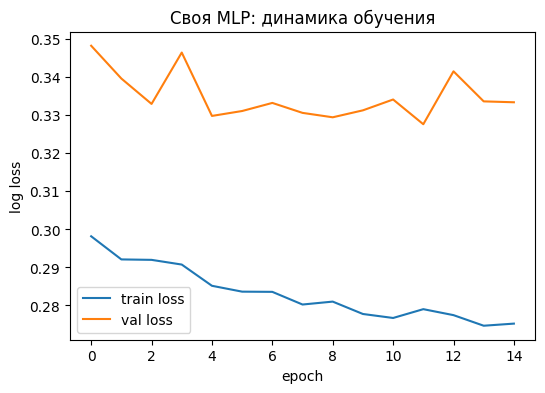

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.plot(my_mlp.history_["train_loss"], label="train loss")
plt.plot(my_mlp.history_["val_loss"], label="val loss")
plt.xlabel("epoch")
plt.ylabel("log loss")
plt.title("Своя MLP: динамика обучения")
plt.legend()
plt.show()


## Сравнение со sklearn `MLPClassifier`

In [17]:
from sklearn.neural_network import MLPClassifier

sk_mlp = MLPClassifier(
    hidden_layer_sizes=64,
    activation="logistic",
    solver="adam",
    learning_rate_init=0.005,
    batch_size=32,
    max_iter=15,
    random_state=RANDOM_STATE,
)
sk_mlp.fit(X_train, y_train)

sk_train_proba = sk_mlp.predict_proba(X_train)[:, 1]
sk_valid_proba = sk_mlp.predict_proba(X_valid)[:, 1]

print("sklearn MLPClassifier")
print("Train Gini:", round(gini_score(y_train, sk_train_proba), 4))
print("Valid Gini:", round(gini_score(y_valid, sk_valid_proba), 4))

print("\nСвоя MLP")
print("Train Gini:", round(gini_score(y_train, train_proba), 4))
print("Valid Gini:", round(gini_score(y_valid, valid_proba), 4))


sklearn MLPClassifier
Train Gini: 0.7767
Valid Gini: 0.4195

Своя MLP
Train Gini: 0.5893
Valid Gini: 0.4773


## Сравнение функций активации: sigmoid, ReLU, cosine


In [18]:
results = {}
for act_name in ["sigmoid", "relu", "cosine"]:
    model = MLP(
        n_hidden=64,
        activation=act_name,
        optimizer="adam",
        lr=0.005,
        batch_size=32,
        n_epochs=15,
        l2=1e-4,
        random_state=RANDOM_STATE,
        verbose=False,
    )
    model.fit(X_train, y_train, X_val=X_valid, y_val=y_valid)

    tr_proba = model.predict_proba(X_train)[:, 1]
    va_proba = model.predict_proba(X_valid)[:, 1]

    results[act_name] = {
        "train_gini": gini_score(y_train, tr_proba),
        "valid_gini": gini_score(y_valid, va_proba),
        "model": model,
    }
    tg = results[act_name]["train_gini"]
    vg = results[act_name]["valid_gini"]
    print(f"{act_name:8s} | train Gini: {tg:.4f} | valid Gini: {vg:.4f}")

best_activation = max(results, key=lambda k: results[k]["valid_gini"])
print(f"\nЛучшая функция активации по valid Gini: {best_activation}")


sigmoid  | train Gini: 0.5893 | valid Gini: 0.4773
relu     | train Gini: 0.6388 | valid Gini: 0.4691
cosine   | train Gini: 0.7665 | valid Gini: 0.4171

Лучшая функция активации по valid Gini: sigmoid


## MLP на PyTorch

In [19]:
TORCH_AVAILABLE = True
try:
    import torch
    import torch.nn as nn
except ImportError:
    TORCH_AVAILABLE = False
    print("PyTorch не установлен. Установи командой:\n"
          "    pip install torch --break-system-packages\n"
          "и перезапусти эту и следующую ячейку.")

if TORCH_AVAILABLE:
    torch.manual_seed(RANDOM_STATE)

    class TorchMLP(nn.Module):
        def __init__(self, n_features, n_hidden):
            super().__init__()
            self.fc1 = nn.Linear(n_features, n_hidden)
            self.act = nn.Sigmoid()
            self.fc2 = nn.Linear(n_hidden, 2)

        def forward(self, x):
            z1 = self.fc1(x)
            a1 = self.act(z1)
            z2 = self.fc2(a1)
            return z2


In [20]:
if TORCH_AVAILABLE:
    device = "cuda" if torch.cuda.is_available() else "cpu"

    X_train_t = torch.tensor(X_train, dtype=torch.float32, device=device)
    y_train_t = torch.tensor(y_train, dtype=torch.long, device=device)
    X_valid_t = torch.tensor(X_valid, dtype=torch.float32, device=device)
    y_valid_t = torch.tensor(y_valid, dtype=torch.long, device=device)

    torch_model = TorchMLP(n_features=X_train.shape[1], n_hidden=64).to(device)
    optimizer = torch.optim.Adam(torch_model.parameters(), lr=0.005, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()

    n_epochs = 15
    batch_size = 32
    n = X_train_t.shape[0]

    for epoch in range(n_epochs):
        perm = torch.randperm(n)
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            xb, yb = X_train_t[idx], y_train_t[idx]

            optimizer.zero_grad()
            logits = torch_model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

        with torch.no_grad():
            val_logits = torch_model(X_valid_t)
            val_loss = criterion(val_logits, y_valid_t).item()
        print(f"epoch {epoch + 1}/{n_epochs} - val_loss: {val_loss:.4f}")

    with torch.no_grad():
        torch_train_proba = torch.softmax(torch_model(X_train_t), dim=1)[:, 1].cpu().numpy()
        torch_valid_proba = torch.softmax(torch_model(X_valid_t), dim=1)[:, 1].cpu().numpy()

    print("\nPyTorch MLP")
    print("Train Gini:", round(gini_score(y_train, torch_train_proba), 4))
    print("Valid Gini:", round(gini_score(y_valid, torch_valid_proba), 4))


epoch 1/15 - val_loss: 0.3392
epoch 2/15 - val_loss: 0.3554
epoch 3/15 - val_loss: 0.3411
epoch 4/15 - val_loss: 0.3361
epoch 5/15 - val_loss: 0.3340
epoch 6/15 - val_loss: 0.3355
epoch 7/15 - val_loss: 0.3298
epoch 8/15 - val_loss: 0.3386
epoch 9/15 - val_loss: 0.3293
epoch 10/15 - val_loss: 0.3302
epoch 11/15 - val_loss: 0.3619
epoch 12/15 - val_loss: 0.3351
epoch 13/15 - val_loss: 0.3535
epoch 14/15 - val_loss: 0.3391
epoch 15/15 - val_loss: 0.3351

PyTorch MLP
Train Gini: 0.5939
Valid Gini: 0.4667


Результат проактически такой же, но быстрее благодаря тому, что фреймворк оптимизирует вычисления на уровне ядра и использует ресурсы железа на максимум. Вот ключевые причины:

* Векторизация операций. PyTorch оперирует тензорами — это позволяет выполнять операции над целыми пакетами данных (батчами) за один вызов, что значительно эффективнее, чем обработка примеров по одному.
* Использование GPU. Фреймворк даёт возможность переносить вычисления на видеокарту (CUDA). Для больших моделей и объёмов данных это даёт прирост скорости в десятки раз по сравнению с CPU.
* Автоматическое дифференцирование (Autograd). PyTorch эффективно строит вычислительный граф и автоматически вычисляет градиенты, что упрощает и ускоряет процесс обучения.
* Оптимизированные встроенные слои. Например, nn.Linear (линейный слой) реализован так, чтобы как можно быстрее выполнять матричные умножения.

## Результаты:

In [21]:
candidates = {
    "my_mlp (sigmoid)": (my_mlp, "custom"),
    "sklearn MLPClassifier": (sk_mlp, "sklearn"),
}
for act_name, res in results.items():
    candidates[f"my_mlp ({act_name})"] = (res["model"], "custom")
if TORCH_AVAILABLE:
    candidates["torch_mlp"] = (torch_model, "torch")

def get_proba(model, kind, X):
    if kind == "custom":
        return model.predict_proba(X)[:, 1]
    elif kind == "sklearn":
        return model.predict_proba(X)[:, 1]
    elif kind == "torch":
        with torch.no_grad():
            xt = torch.tensor(X, dtype=torch.float32, device=device)
            return torch.softmax(model(xt), dim=1)[:, 1].cpu().numpy()

valid_scores = {}
for name, (model, kind) in candidates.items():
    proba = get_proba(model, kind, X_valid)
    valid_scores[name] = gini_score(y_valid, proba)

best_name = max(valid_scores, key=valid_scores.get)
best_model, best_kind = candidates[best_name]
print("Valid Gini по всем моделям:")
for name, score in sorted(valid_scores.items(), key=lambda kv: -kv[1]):
    print(f"  {name:25s}: {score:.4f}")
print(f"\nЛучшая модель по valid Gini: {best_name}")


Valid Gini по всем моделям:
  my_mlp (sigmoid)         : 0.4773
  my_mlp (relu)            : 0.4691
  torch_mlp                : 0.4667
  sklearn MLPClassifier    : 0.4195
  my_mlp (cosine)          : 0.4171

Лучшая модель по valid Gini: my_mlp (sigmoid)


In [22]:
train_proba_best = get_proba(best_model, best_kind, X_train)
valid_proba_best = get_proba(best_model, best_kind, X_valid)
test_proba_best = get_proba(best_model, best_kind, X_test)

train_gini_best = gini_score(y_train, train_proba_best)
valid_gini_best = gini_score(y_valid, valid_proba_best)
test_gini_best = gini_score(y_test, test_proba_best)

print(f"Лучшая модель: {best_name}")
print(f"Train Gini: {train_gini_best:.4f}")
print(f"Valid Gini: {valid_gini_best:.4f}")
print(f"Test  Gini: {test_gini_best:.4f}")
print(f"\nПадение качества valid -> test: {valid_gini_best - test_gini_best:.4f}")


Лучшая модель: my_mlp (sigmoid)
Train Gini: 0.5893
Valid Gini: 0.4773
Test  Gini: 0.4750

Падение качества valid -> test: 0.0023


Падение качества модели незначительное, что означает, что она не переобучена и хорошо обобщает данные